# Q2: Does road design predict KSI crashes beyond crash history?

Q1 (`q1_ksi_risk.ipynb`) ranks sites using crash history alone. Busy places have more crashes of every kind, so crash volume partly stands in for **exposure** (traffic). Here we ask whether the road itself (intersection geometry, lanes, width, speed limit and road type) adds information beyond that.

**Data:** DCP's LION street network (`data/lion/lion.gdb`, downloaded by hand). Every LION street within 100 ft of a Q1 site centroid describes the site (`preprocessing/roadway.py`):

| Group | Features |
|---|---|
| Intersection geometry | legs at the nearest intersection (3, 4, 5+ vs. none), intersections within 100 ft |
| Lanes and width | travel lanes and curb-to-curb width of the biggest street (divided roadbeds summed), median lane width |
| Speed limit | posted limit: 20 or less, 30–35, 40+ (vs. the 25 mph default) |
| Road type | one-way street, highway or ramp, bike lane, truck route |

Sites with missing values get the median and a `roadway_missing` flag.

**Not yet included: traffic volume.** It isn't in LION, and DOT counts cover only some streets, so it will be a separate join. Until then, lanes, width and truck routes partly stand in for volume, and their effects mix "busy" with "badly designed".

**Method:** Q1's negative binomial model and expanding-window validation (fit on earlier years, test on 2024 and 2025), unchanged. Experiment 1 adds each group to Q1's crash-history model and measures the change; Experiment 2 reads each attribute's effect as a rate ratio.

In [1]:
import logging
import sys

sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from model.count_models import NegativeBinomialModel
from preprocessing.panel import load_panel
from preprocessing.roadway import ROADWAY_FEATURES, add_roadway_features, load_roadway_features
from validation.validate import ValidationConfig, evaluate, poisson_deviance

logging.getLogger().setLevel(logging.WARNING)  # INFO shows rows dropped at each step

# same palette and style as q1_ksi_risk.ipynb
WITH_HISTORY, WITHOUT_HISTORY = "#2a78d6", "#eb6834"
INK, INK_2, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": INK_2,
    "axes.labelcolor": INK_2, "text.color": INK, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 9.5,
})
pd.set_option("display.precision", 3)

In [2]:
panel, scoring, sites = load_panel()
roadway = load_roadway_features(sites)
panel = add_roadway_features(panel, roadway)
print(f"{len(sites):,} sites, {len(panel):,} site-years ({panel.year.min()}-{panel.year.max()})")

89,073 sites, 356,292 site-years (2022-2025)


## 0. What the roads at crash sites look like
Coverage first: how many sites have each attribute, and the typical values.

In [3]:
coverage = pd.DataFrame({
    "sites with a value": roadway.drop(columns="site_id").notna().mean(),
    "median": roadway.drop(columns="site_id").median(numeric_only=True),
})
print(f"At an intersection (3+ legs): {(roadway.legs >= 3).mean():.0%} of sites")
print(roadway.legs.clip(upper=5).value_counts(normalize=True).sort_index().rename("share of sites by legs (5 = 5+)").to_string())
coverage.style.format({"sites with a value": "{:.0%}", "median": "{:.1f}"})

At an intersection (3+ legs): 46% of sites
legs
0    0.541
3    0.154
4    0.212
5    0.093


,sites with a value,median
bike_lane,99%,nan
highway,99%,nan
lane_width_ft,97%,13.5
lanes,99%,2.0
legs,100%,0.0
n_intersections,100%,0.0
n_streets,99%,1.0
one_way,99%,nan
speed_limit,99%,25.0
truck_route,99%,nan


In [4]:
# lanes, width and speed limit all track road size, so their separate effects are hard to pull apart
roadway[["legs", "lanes", "width_ft", "lane_width_ft", "speed_limit"]].corr(method="spearman").round(2)

,legs,lanes,width_ft,lane_width_ft,speed_limit
legs,1.00,0.29,0.30,-0.03,0.00
lanes,0.29,1.00,0.80,-0.34,0.38
width_ft,0.30,0.80,1.00,0.04,0.32
lane_width_ft,-0.03,-0.34,0.04,1.00,-0.08
speed_limit,0.00,0.38,0.32,-0.08,1.00


## 1. Do roadway attributes improve the Q1 ranking?
Each row is a model, scored on 2024 and 2025 (averaged).
- **Top-100 / top-1,000 capture:** share of next year's KSI crashes at the model's top sites (as in Q1). With few KSI crashes per year, top-100 moves by chance, so differences under about one point aren't meaningful.
- **Deviance:** how well predicted counts match observed counts at *every* site (lower is better). This separates models whose top lists barely differ.

"+ group" adds one group to crash history; "all − group" drops one group from the full model, showing what it adds that the others don't; "roadway only" uses no crash history at all.

In [5]:
HISTORY = [f"log1p_{c}_lag3" for c in
           ["pdo", "injury_nonsevere", "ksi_nonfatal", "fatal", "ped_injured", "cyc_injured"]]
GROUPS = {
    "Intersection geometry": ["legs_3", "legs_4", "legs_5plus", "n_intersections"],
    "Lanes and width": ["lanes", "width_10ft", "lane_width_ft"],
    "Speed limit": ["speed_20_or_less", "speed_30_35", "speed_40_plus"],
    "Road type": ["one_way", "highway", "bike_lane", "truck_route"],
}
ALL_ROADWAY = [f for g in GROUPS.values() for f in g] + ["roadway_missing"]
assert set(ALL_ROADWAY) == set(ROADWAY_FEATURES)

specs = {"Crash history (Q1 model)": HISTORY}
specs |= {f"+ {g}": HISTORY + cols + ["roadway_missing"] for g, cols in GROUPS.items()}
specs["+ all roadway"] = HISTORY + ALL_ROADWAY
specs |= {f"all − {g}": HISTORY + [f for f in ALL_ROADWAY if f not in cols] for g, cols in GROUPS.items()}
specs["Roadway only (no crash history)"] = ALL_ROADWAY

config = ValidationConfig()
rows = []
for name, features in specs.items():
    capture, _, preds = evaluate(lambda f=features: NegativeBinomialModel(f), panel, config)
    by_k = capture.groupby("k")["capture"].mean()
    deviance = preds.groupby("year").apply(lambda d: poisson_deviance(d.ksi, d.pred)).mean()
    rows.append({"model": name, "top 100": by_k[100], "top 1,000": by_k[1000], "deviance": deviance})

results = pd.DataFrame(rows).set_index("model")
base = results.loc["Crash history (Q1 model)"]
results["deviance vs Q1"] = results["deviance"] / base["deviance"] - 1
results.style.format({"top 100": "{:.1%}", "top 1,000": "{:.1%}", "deviance": "{:.4f}",
                      "deviance vs Q1": "{:+.2%}"})

,top 100,"top 1,000",deviance,deviance vs Q1
model,,,,
Crash history (Q1 model),2.6%,15.8%,0.1638,+0.00%
+ Intersection geometry,2.8%,16.0%,0.1612,-1.60%
+ Lanes and width,2.3%,15.7%,0.1626,-0.74%
+ Speed limit,2.7%,15.8%,0.1637,-0.09%
+ Road type,2.8%,15.5%,0.1630,-0.48%
+ all roadway,2.5%,15.9%,0.1597,-2.48%
all − Intersection geometry,2.5%,15.9%,0.1623,-0.91%
all − Lanes and width,2.8%,15.5%,0.1606,-1.97%
all − Speed limit,2.6%,15.9%,0.1597,-2.48%


## 2. Which attributes matter, and by how much?
Rate ratios from the full model fit on all years: the multiplier on expected KSI crashes for a one-unit change (one lane, 10 ft of width, 1 ft of lane width, one intersection), or for having the feature against its reference. Intervals are 95%, clustered by site.

The two fits answer different questions:
- **Without crash history:** the attribute's total association with KSI. This includes the crashes the design produces at every severity.
- **With crash history:** what the attribute adds once Q1's history is known. It is usually smaller, because history already reflects the road's design.

Neither is a causal effect: wide, fast roads also carry more traffic, and traffic volume isn't in the model yet.

In [6]:
LABELS = {
    "legs_3": "3-leg intersection", "legs_4": "4-leg intersection", "legs_5plus": "5+ leg intersection",
    "n_intersections": "Intersections within 100 ft", "lanes": "Travel lanes (per lane)",
    "width_10ft": "Street width (per 10 ft)", "lane_width_ft": "Lane width (per ft)",
    "speed_20_or_less": "Speed limit ≤ 20", "speed_30_35": "Speed limit 30–35",
    "speed_40_plus": "Speed limit 40+", "one_way": "One-way street", "highway": "Highway or ramp",
    "bike_lane": "Bike lane", "truck_route": "Truck route",
}
fits = {
    "Roadway only": NegativeBinomialModel(ALL_ROADWAY),
    "Roadway + crash history": NegativeBinomialModel(HISTORY + ALL_ROADWAY),
}
effects = {}
for name, model in fits.items():
    model.fit(panel, panel["ksi"], groups=panel["site_id"])
    effects[name] = model.coefficients().loc[list(LABELS), ["ratio", "ci_low", "ci_high", "p_value"]]

table = pd.concat(effects, axis=1).rename(index=LABELS)
table.style.format("{:.2f}").format("{:.3f}", subset=[(n, "p_value") for n in fits])

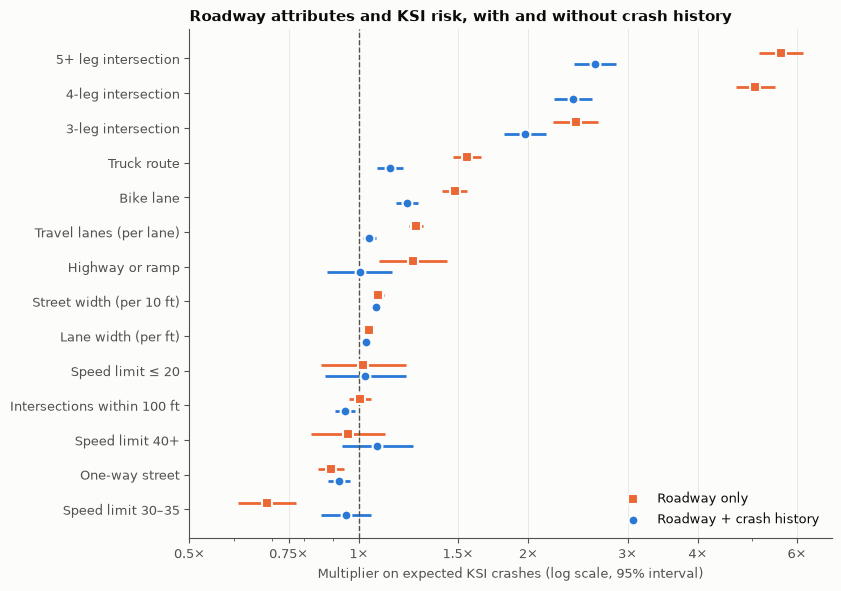

In [7]:
order = effects["Roadway only"]["ratio"].sort_values().index
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(8.5, 6))
for (name, eff), color, marker, offset in zip(
    effects.items(), [WITHOUT_HISTORY, WITH_HISTORY], ["s", "o"], [0.17, -0.17]
):
    eff = eff.loc[order]
    ax.hlines(y + offset, eff.ci_low, eff.ci_high, color=color, linewidth=2)
    ax.scatter(eff.ratio, y + offset, color=color, marker=marker, s=50, zorder=3,
               edgecolor=SURFACE, linewidth=1.5, label=name)
ax.axvline(1, color=INK_2, linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 3, 4, 6])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}×"))
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks(y, [LABELS[f] for f in order])
ax.grid(axis="y", visible=False)
ax.set_xlabel("Multiplier on expected KSI crashes (log scale, 95% interval)")
ax.set_title("Roadway attributes and KSI risk, with and without crash history")
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()

## Next steps
- **Traffic volume:** join DOT Automated Traffic Volume Counts and rerun both experiments on the sites with counts, to separate design from exposure.
- **Non-linear effects:** gradient boosting (Poisson objective) with SHAP, in the same validation.
- **Sites with no crash history:** use every LION intersection, including those with zero crashes, as the unit, so the model can flag risky designs before a severe crash happens.